# Entanglement: From Your Hands to Real Hardware

**See it with Qubis. Build it with Qiskit. Run it on a real quantum computer.**

**Question.** Can I experience entanglement, represent it mathematically, build the circuit, simulate it, run it on hardware, and interpret the results?

An initiative by Quantum Global Group.

## 00. Welcome

This lab builds one state and stays with it long enough to understand it.

```text
|Phi+> = (|00> + |11>) / sqrt(2)
```

That state is called a Bell state. Two of the four computational outcomes are possible. The other two have amplitude zero. The lab's job is to see why, to build the circuit that prepares the state, to sample it, and to say what the sample does not prove.

You will follow one order: see it, understand it, map it, code it, run it, measure it, interpret it, find your pathway.

Qubi, the physical model, comes from [Qolour](https://www.qolour.com/). Their Bell Pairs lesson is linked in section 08. This notebook does not copy that lesson. Qiskit and IBM Quantum are documented at [IBM Quantum](https://quantum.cloud.ibm.com/docs/). The pages this lab relies on are listed in [resources/official-docs.md](../../resources/official-docs.md).

**PAUSE HERE.** Write the question of the lab in your own words on the [worksheet](STUDENT_WORKSHEET.md). Include a state, a circuit, and an interpretation.


## 01. Get access

There are three levels. Hardware is never required for the foundations.

| Level | What you do in this notebook | IBM account |
| --- | --- | --- |
| 1. See and understand | Read, predict, and write the worksheet. Use a Qubi kit if one is in the room. | None |
| 2. Code and simulate | Run every cell below. The sampler is local. | None |
| 3. Run on real hardware | After an invitation, one deliberate job in section 14. | A Classroom seat |

The public seat policy is [docs/qpu-access.md](../../docs/qpu-access.md). Capacity is about 100 seats. An invitation is manual. This notebook cannot grant one, and it does not ask for your email.

The learning community is [Quantum for the Qulture on Skool](https://www.skool.com/quantum-for-the-qulture-8361). Video, a guided Qubi demonstration, discussion, and hardware onboarding live there. This file is not locked behind membership.

A Classroom seat starts there. Join Skool, complete Start Here, and submit in Skool the email address that should receive the IBM invitation. Kevin A. Robinson reviews the request and sends the invitation himself. There is no public IBM invite link. Do not put that email in this notebook or in the repository.

Leave `RUN_REAL_HARDWARE` set to `False` unless you are on level 3 and you intend to spend one job.


## 02. Set up your environment

Python 3.10 or newer is required. This notebook was executed with Python 3.12.3 and the packages in [requirements.txt](../../requirements.txt): Qiskit 2.6.2, NumPy 2.5.5, and Matplotlib 3.11.2. No IBM credential was present.

From the repository root:

```bash
python -m venv .venv
source .venv/bin/activate
pip install -r requirements.txt
python tests/smoke_lab001.py
```

The smoke test rebuilds the mathematics in this lab and does not contact IBM.

**FIND IT IN THE DOCS.** Open [Exact simulation with Qiskit SDK primitives](https://quantum.cloud.ibm.com/docs/en/qiskit/simulate-with-qiskit-sdk-primitives) and find `StatevectorSampler`. Notice that a circuit passed to a sampler must include measurements.


In [1]:
import matplotlib
import numpy as np
import qiskit
from qiskit import QuantumCircuit

SEED = 7
SHOTS = 1024

print("qiskit", qiskit.__version__)
print("numpy", np.__version__)
print("matplotlib", matplotlib.__version__)
print("SEED", SEED)
print("SHOTS", SHOTS)
print("This cell does not read an IBM account.")


qiskit 2.6.2
numpy 2.5.5
matplotlib 3.11.2
SEED 7
SHOTS 1024
This cell does not read an IBM account.


## 03. Learn the language

Each word below is used later. Read one, then the next.

A **qubit** is a quantum system with two levels. We call those levels 0 and 1. The lab uses two qubits.

A **state** is the complete description we are willing to use for the system before we measure. In this lab a state is a column of complex amplitudes, one amplitude per basis label.

A **basis** is the set of labels we expand that column in. The computational basis for one qubit is `|0>` and `|1>`. For two qubits it is `|00>`, `|01>`, `|10>`, and `|11>`.

A **gate** is a reversible operation that sends one state to another. Section 05 uses I, X, H, and CX.

A **circuit** is an ordered list of gates, followed, when we want bits, by measurement.

A **measurement** in this lab is a computational-basis measurement. It returns a classical bit for each qubit. One run returns one bitstring. That single return is one **shot**.

A **probability** is the chance of a bitstring. For a state, the probability of a basis label is the squared magnitude of its amplitude. A finite number of shots approximates that probability and does not reproduce it exactly.

An **observable** is a question with numerical answers. Section 07 uses the Pauli observables I, X, Y, and Z. An expectation value is the average of those answers on a state.

A **backend** is the thing that runs a circuit. In this notebook the working backend is a local statevector simulator. A quantum processor is a different backend, used only in section 14, and only if you turn that section on.

**CHECK YOUR UNDERSTANDING.** On the worksheet, define qubit, state, and shot without using the other two words in the definition.


## 04. Quantum states

A column vector lists amplitudes. The top entry is the amplitude of the first basis label.

For one qubit:

```text
|0> = [1, 0]
|1> = [0, 1]
|+> = [|0> + |1>] / sqrt(2)
|-> = [|0> - |1>] / sqrt(2)
```

`|+>` and `|->` are superpositions: more than one amplitude is nonzero. The minus sign in `|->` is a relative phase. Both amplitudes still have the same size, so a computational measurement of either state returns 0 or 1 with probability 1/2. The sign matters when a later gate treats the two amplitudes differently.

A state is normalized when the squared magnitudes of the amplitudes add to 1. That sum is the total probability.

For two qubits, Qiskit reads a label from left to right as qubit 1, then qubit 0. The rightmost character is qubit 0. `|01>` means qubit 1 is 0 and qubit 0 is 1. The statevector stores the amplitude of `|x>` at index `x`, so index 0 is `|00>`, index 1 is `|01>`, index 2 is `|10>`, and index 3 is `|11>`.

The Bell state we want is an equal superposition of the two labels in which the bits agree:

```text
|Phi+> = (|00> + |11>) / sqrt(2)
```

The other three Bell states exist. This lab does not build them.

**FIND IT IN THE DOCS.** On [Bit-ordering in the Qiskit SDK](https://quantum.cloud.ibm.com/docs/en/qiskit/bit-ordering), find the sentence that says which character of a string is bit 0.


In [2]:
from qiskit.quantum_info import Statevector

def show_state(label):
    data = np.round(Statevector.from_label(label).data.astype(complex), 4)
    print(f"|{label}>")
    for index, amplitude in enumerate(data):
        print(f"  index {index}: {amplitude}")

print("One qubit")
for label in ("0", "1", "+", "-"):
    show_state(label)

print("Two qubits, computational basis")
for label in ("00", "01", "10", "11"):
    show_state(label)

plus = Statevector.from_label("+")
print("normalization of |+>:", round(float(np.linalg.norm(plus.data)), 6))
print("P(0) for |+>:", round(float(plus.probabilities_dict().get("0", plus.probabilities()[0])), 6))
print("P(0) for |->:", round(float(Statevector.from_label("-").probabilities()[0]), 6))


One qubit
|0>
  index 0: (1+0j)
  index 1: 0j
|1>
  index 0: 0j
  index 1: (1+0j)
|+>
  index 0: (0.7071+0j)
  index 1: (0.7071+0j)
|->
  index 0: (0.7071+0j)
  index 1: (-0.7071+0j)
Two qubits, computational basis
|00>
  index 0: (1+0j)
  index 1: 0j
  index 2: 0j
  index 3: 0j
|01>
  index 0: 0j
  index 1: (1+0j)
  index 2: 0j
  index 3: 0j
|10>
  index 0: 0j
  index 1: 0j
  index 2: (1+0j)
  index 3: 0j
|11>
  index 0: 0j
  index 1: 0j
  index 2: 0j
  index 3: (1+0j)
normalization of |+>: 1.0
P(0) for |+>: 0.5
P(0) for |->: 0.5


The printed `|01>` column has its `1` at index 1. That index is the integer value of the bitstring `01`, and the rightmost bit of that string is qubit 0.

`|+>` and `|->` have the same computational probabilities. The relative phase is invisible to a Z measurement and visible to other measurements. Section 07 names those measurements.


## 05. Gates I, X, H, and CX

Four gates are enough for this state.

**I, identity.** Symbol: I. Input and output are the same vector. The matrix is `[[1, 0], [0, 1]]`. It matters because "do nothing" has to be an operation we can write down, including inside an observable.

**X, bit flip.** Symbol: X. `|0>` becomes `|1>` and `|1>` becomes `|0>`. The matrix is `[[0, 1], [1, 0]]`. It is the quantum version of NOT, and it is the action CX applies to its target when the control is 1.

**H, Hadamard.** Symbol: H. `|0>` becomes `|+>` and `|1>` becomes `|->`. The matrix is `[[1, 1], [1, -1]] / sqrt(2)`. It matters because the Bell circuit needs a superposition on the control before CX can spread that superposition to both qubits.

**CX, controlled NOT.** Symbol: a dot on the control and a plus on the target. In this lab the control is qubit 0 and the target is qubit 1, written `cx(0, 1)`. If the control is 0, the target is unchanged. If the control is 1, the target flips. The next section shows that this basis rule is not the whole gate, and that it does not by itself create entanglement.

On a Qiskit drawing, qubit 0 is the top wire.


In [3]:
from qiskit.quantum_info import Operator

def show_matrix(title, circuit):
    print(title)
    print(np.round(Operator(circuit).data, 4))

identity = QuantumCircuit(1)
flip = QuantumCircuit(1)
flip.x(0)
hadamard = QuantumCircuit(1)
hadamard.h(0)
controlled = QuantumCircuit(2)
controlled.cx(0, 1)

show_matrix("I", identity)
show_matrix("X", flip)
show_matrix("H", hadamard)
show_matrix("CX with control qubit 0 and target qubit 1", controlled)

print("X applied to |0>:", np.round(Statevector.from_label("0").evolve(flip).data, 4))
print("H applied to |0>:", np.round(Statevector.from_label("0").evolve(hadamard).data, 4))
print(controlled.draw(fold=40))


I
[[1.+0.j 0.+0.j]
 [0.+0.j 1.+0.j]]
X
[[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]
H
[[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]
CX with control qubit 0 and target qubit 1
[[1.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 1.+0.j]
 [0.+0.j 0.+0.j 1.+0.j 0.+0.j]
 [0.+0.j 1.+0.j 0.+0.j 0.+0.j]]
X applied to |0>: [0.+0.j 1.+0.j]
H applied to |0>: [0.7071+0.j 0.7071+0.j]
          
q_0: ──■──
     ┌─┴─┐
q_1: ┤ X ├
     └───┘


The CX matrix is the one in the bit-ordering guide for `cx(0, 1)`: it exchanges the amplitudes of `|01>` and `|11>` and leaves `|00>` and `|10>` in place. Section 06 checks that claim on each basis input.

**FIND IT IN THE DOCS.** On the same bit-ordering page, find the CX matrix and compare it with the matrix this cell printed.


## 06. CNOT rules

The basis rule is small enough to memorize.

| Control | Target before | Target after | Result, control then target |
| --- | --- | --- | --- |
| 0 | 0 | 0 | 00 |
| 0 | 1 | 1 | 01 |
| 1 | 0 | 1 | 11 |
| 1 | 1 | 0 | 10 |

Control 0: the target is unchanged. Control 1: the target flips.

That table writes the control on the left. Qiskit prints qubit 1, our target, on the left, and qubit 0, our control, on the right. The state is the same. The string can look different. The cell prints both writings.

The basis table is not the full gate. CX is linear. It acts on a superposition by acting on each piece and adding the results. A basis input is mapped to a basis output, so the output is still a product state: each qubit has its own definite bit. Entanglement shows up when the control is in a superposition and the target starts in a definite state, which is what H on qubit 0 prepares. H on the target, with the control left in `|0>`, does not do that. The control is 0 for every term, so the target never flips, and the state stays a product.

**PAUSE HERE.** Fill the CNOT table on the worksheet before you run the next cell.

**TRY THIS.** After the cell, cover the purity numbers and predict what happens if the H on the control is replaced by X.


In [4]:
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import partial_trace

def qiskit_bitstring(state):
    probabilities = {str(label): float(value) for label, value in state.probabilities_dict().items()}
    return max(probabilities, key=probabilities.get)

print("Basis inputs. Control is qubit 0. Target is qubit 1.")
for control, target_before in ((0, 0), (0, 1), (1, 0), (1, 1)):
    circuit = QuantumCircuit(2)
    if control == 1:
        circuit.x(0)
    if target_before == 1:
        circuit.x(1)
    circuit.cx(0, 1)
    target_after = target_before if control == 0 else 1 - target_before
    written_control_first = f"{control}{target_after}"
    printed = qiskit_bitstring(Statevector.from_instruction(circuit))
    print(
        f"control {control}, target {target_before} -> {target_after}; "
        f"control-then-target {written_control_first}; Qiskit string {printed}"
    )

print("Bit order check: X on one qubit, then measure.")
for qubit in (0, 1):
    probe = QuantumCircuit(2)
    probe.x(qubit)
    probe.measure_all()
    counts = (
        StatevectorSampler()
        .run([probe], shots=32)
        .result()[0]
        .data.meas.get_counts()
    )
    print(f"X on qubit {qubit}:", {str(k): int(v) for k, v in counts.items()})

def purity(circuit):
    reduced = partial_trace(Statevector.from_instruction(circuit), [1])
    return round(float(np.real(reduced.purity())), 4)

only_cx = QuantumCircuit(2)
only_cx.cx(0, 1)
h_on_control = QuantumCircuit(2)
h_on_control.h(0)
h_on_control.cx(0, 1)
h_on_target = QuantumCircuit(2)
h_on_target.h(1)
h_on_target.cx(0, 1)
x_on_control = QuantumCircuit(2)
x_on_control.x(0)
x_on_control.cx(0, 1)

print("purity, CX on |00>:", purity(only_cx))
print("purity, H on control then CX:", purity(h_on_control))
print("purity, H on target then CX:", purity(h_on_target))
print("purity, X on control then CX:", purity(x_on_control))


Basis inputs. Control is qubit 0. Target is qubit 1.
control 0, target 0 -> 0; control-then-target 00; Qiskit string 00
control 0, target 1 -> 1; control-then-target 01; Qiskit string 10
control 1, target 0 -> 1; control-then-target 11; Qiskit string 11
control 1, target 1 -> 0; control-then-target 10; Qiskit string 01
Bit order check: X on one qubit, then measure.
X on qubit 0: {'01': 32}
X on qubit 1: {'10': 32}
purity, CX on |00>: 1.0
purity, H on control then CX: 0.5
purity, H on target then CX: 1.0
purity, X on control then CX: 1.0


A reduced purity of 1 is a product state. A reduced purity of 0.5, for one qubit of a pure two-qubit state, is a maximally entangled state. CX on `|00>` stays at 1. H on the control, then CX, falls to 0.5. H on the target stays at 1, because the control bit is 0 in every term. X on the control also stays at 1: the input was a basis state, and the output is the basis state `|11>`.

The X-on-qubit-0 sample prints `01`. The rightmost character flipped. The X-on-qubit-1 sample prints `10`. The leftmost character flipped. That is the string order for the rest of the lab.

**CHECK YOUR UNDERSTANDING.** Which single change, H on the control or H on the target, produced the purity below 1?


## 07. States and observables

Keep this sequence in view:

**state, gate, new state, observable, classical result.**

I, X, Y, and Z are the single-qubit Pauli observables.

| Observable | Beginner meaning | Eigenvalues | A `+1` eigenstate |
| --- | --- | --- | --- |
| I | The question whose answer is always +1 | +1 | Every state |
| X | Which way the superposition leans between `|+>` and `|->` | +1 and -1 | `|+>` |
| Y | The question that notices an imaginary relative phase | +1 and -1 | `(|0> + i|1>) / sqrt(2)` |
| Z | Which computational bit | +1 and -1 | `|0>` |

A computational measurement reports a bit, not the eigenvalue. Bit 0 corresponds to Z eigenvalue +1. Bit 1 corresponds to Z eigenvalue -1.

For two qubits, write a Pauli string with qubit 0 on the right. `ZZ` means Z on both qubits. `IZ` means Z on qubit 0 only. `ZI` means Z on qubit 1 only.

On `|Phi+>` the three correlations are:

```text
<ZZ> = +1
<XX> = +1
<YY> = -1
```

`<ZZ> = +1` means the two Z results agree: both bits 0, or both bits 1. It does not mean each bit is 0. `<ZI>` and `<IZ>` are 0, so each qubit, looked at alone, is random in the computational basis. The certainty is in the relationship.

`<XX> = +1` means the X results agree. `<YY> = -1` means the Y results disagree. Those three numbers together are a much sharper description than the Z histogram alone. A Bell inequality, which would test nonlocality, is a later lab. This page does not claim one, and it does not claim a quantum advantage.


In [5]:
from qiskit.quantum_info import SparsePauliOp

for label in ("I", "X", "Y", "Z"):
    print(label)
    print(np.round(SparsePauliOp(label).to_matrix(), 4))

zero = Statevector.from_label("0")
one = Statevector.from_label("1")
plus = Statevector.from_label("+")
minus = Statevector.from_label("-")
print("<0|Z|0> =", round(float(np.real(zero.expectation_value(SparsePauliOp("Z")))), 4))
print("<1|Z|1> =", round(float(np.real(one.expectation_value(SparsePauliOp("Z")))), 4))
print("<+|X|+> =", round(float(np.real(plus.expectation_value(SparsePauliOp("X")))), 4))
print("<-|X|-> =", round(float(np.real(minus.expectation_value(SparsePauliOp("X")))), 4))

phi_plus = Statevector(
    (Statevector.from_label("00").data + Statevector.from_label("11").data) / np.sqrt(2)
)
print("Mathematical |Phi+> amplitudes:", np.round(phi_plus.data, 4))
for label in ("ZZ", "XX", "YY", "ZI", "IZ"):
    value = float(np.real(phi_plus.expectation_value(SparsePauliOp(label))))
    print(f"<{label}> =", round(value, 6))


I
[[1.+0.j 0.+0.j]
 [0.+0.j 1.+0.j]]
X
[[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]
Y
[[0.+0.j 0.-1.j]
 [0.+1.j 0.+0.j]]
Z
[[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]]
<0|Z|0> = 1.0
<1|Z|1> = -1.0
<+|X|+> = 1.0
<-|X|-> = -1.0
Mathematical |Phi+> amplitudes: [0.7071+0.j 0.    +0.j 0.    +0.j 0.7071+0.j]
<ZZ> = 1.0
<XX> = 1.0
<YY> = -1.0
<ZI> = 0.0
<IZ> = 0.0


The Y matrix is imaginary. You do not need to multiply it by hand in this lab. You do need to see that Y is a different question from X and Z, and that `|Phi+>` answers it with -1.

The same three correlations will be computed again from the circuit, with the estimator, in section 12. Two routes to the same numbers are the check.


## 08. Qubi experience

**PAUSE HERE** if a Qubi kit is in the room. Do the observation before you read the vector again.

The physical activity is Qolour's lesson, [Bell Pairs](https://www.qolour.com/educator-course/bell-pairs). Use the controls that page actually provides. This notebook does not add any. If the page is unavailable, answer the prompts in discussion. That is a verbal stand-in, not the physical model. Original demonstrations from this initiative are not published yet; the note is [assets/future-demos.md](assets/future-demos.md).

Write these before anyone says "Bell state":

1. What do you observe?
2. What appears connected?
3. What changes when you change one model?
4. What pattern is still there when you repeat the activity?
5. How is that different from two models that never interact?

Then make the turn this lab is built around. We experienced a pattern physically. A pattern we can argue about needs mathematics. The vector in section 04 is that mathematics. The circuit in section 10 is the same state written as operations.

Qubi is the visualization. Qiskit is the representation. An IBM quantum processor is hardware execution. A result from one of them is a result from that one.


## 09. Map the Bell state

Start in `|00>`, which is the column `[1, 0, 0, 0]`.

Apply H to qubit 0. Qubit 0 becomes `|+>` and qubit 1 stays `|0>`:

```text
(|00> + |01>) / sqrt(2)
```

`|01>` means qubit 0 is 1 and qubit 1 is 0. The control of the coming CX is qubit 0, so the second term is the term where the control is on.

Apply CX with control 0 and target 1. The `|00>` term stays `|00>`. The `|01>` term has control 1 and target 0, so the target flips and the term becomes `|11>`.

```text
(|00> + |11>) / sqrt(2)
```

That is `|Phi+>`. Nothing in the algebra says that one qubit told the other a bit. The gate rewrote one joint vector into another joint vector.

**PAUSE HERE.** Write the column you expect after H, and the column you expect after CX, on the worksheet. Then run the cell.


In [6]:
mapped = QuantumCircuit(2)
print("start |00>:", np.round(Statevector.from_label("00").data, 4))
mapped.h(0)
after_h = Statevector.from_instruction(mapped)
def tidy(data):
    values = np.array(data, dtype=complex)
    values.real[np.abs(values.real) < 1e-10] = 0
    values.imag[np.abs(values.imag) < 1e-10] = 0
    return np.round(values, 4)

print("after H on qubit 0:", tidy(after_h.data))
mapped.cx(0, 1)
after_cx = Statevector.from_instruction(mapped)
print("after CX(0, 1):", tidy(after_cx.data))
target = (Statevector.from_label("00").data + Statevector.from_label("11").data) / np.sqrt(2)
print("matches |Phi+>:", bool(np.allclose(after_cx.data, target)))


start |00>: [1.+0.j 0.+0.j 0.+0.j 0.+0.j]
after H on qubit 0: [0.7071+0.j 0.7071+0.j 0.    +0.j 0.    +0.j]
after CX(0, 1): [0.7071+0.j 0.    +0.j 0.    +0.j 0.7071+0.j]
matches |Phi+>: True


Index 0 and index 3 hold `1/sqrt(2)`, about 0.7071. Index 1 and index 2 are 0. Those indexes are `|00>` and `|11>`. The map matches the state from section 07.


## 10. Build the circuit

The circuit is the map, written as gates.

1. Start in `|00>`. Qiskit circuits start there.
2. H on qubit 0 creates the superposition `(|00> + |01>) / sqrt(2)`.
3. CX with control 0 and target 1 rewrites the second term to `|11>`.
4. The statevector of the circuit is `|Phi+>`.

Draw it before you trust it. Qubit 0 is on top. The control of CX is the dot on that wire.


In [7]:
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)
print(bell.draw(fold=60))
prepared = Statevector.from_instruction(bell)
print("circuit amplitudes:", np.round(prepared.data, 4))
print("depth before measurement:", bell.depth())
print("operations:", dict(bell.count_ops()))


     ┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘
circuit amplitudes: [0.7071+0.j 0.    +0.j 0.    +0.j 0.7071+0.j]
depth before measurement: 2
operations: {'h': 1, 'cx': 1}


Depth 2 counts H and then CX. Measurement is not in this circuit yet. The sampler in the next section needs a measured copy. The estimator in section 12 needs this copy, without measurements.


## 11. Simulate locally

**PAUSE HERE.** Predict the sample before you run it.

You should see only `00` and `11`. You should see about half of the shots in each, and you should not expect the split to be exactly 512 and 512. Each shot is an independent draw. A finite sample wanders around the ideal probability.

The agreement score is `(n00 + n11) / shots`. On this simulator it can be 1 even while `n00` and `n11` differ. The score says how much of the sample landed on the two allowed strings. It does not say the state is entangled. A random mixture of `|00>` and `|11>` would also score 1 in this basis.

The sampler is `StatevectorSampler`, a local statevector implementation of the version-2 sampler primitive. Seed 7 makes this particular sample repeatable. A different seed moves the split and should not create `01` or `10` for this circuit.


        ┌───┐      ░ ┌─┐   
   q_0: ┤ H ├──■───░─┤M├───
        └───┘┌─┴─┐ ░ └╥┘┌─┐
   q_1: ─────┤ X ├─░──╫─┤M├
             └───┘ ░  ║ └╥┘
meas: 2/══════════════╩══╩═
                      0  1 
Sampler PUB is a one-element tuple. Circuit qubits: 2
Classical register: meas


counts: {'11': 507, '00': 517}
n00 517 n11 507 n01 0 n10 0
agreement (n00 + n11) / shots = 1.0
imbalance n00 - n11 = 10
Ideal probabilities: P(00) = P(11) = 0.5, P(01) = P(10) = 0.


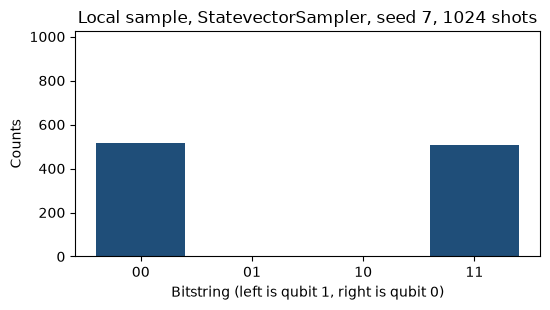

In [8]:
from IPython.display import display
from qiskit.primitives import StatevectorSampler
import matplotlib.pyplot as plt

bell_measured = bell.copy()
bell_measured.measure_all()
print(bell_measured.draw(fold=60))

sampler_pub = (bell_measured,)
print("Sampler PUB is a one-element tuple. Circuit qubits:", sampler_pub[0].num_qubits)
print("Classical register:", sampler_pub[0].cregs[0].name)

local_sampler = StatevectorSampler(seed=SEED)
local_result = local_sampler.run([sampler_pub], shots=SHOTS).result()[0]
raw_counts = local_result.data.meas.get_counts()
counts = {str(bit): int(value) for bit, value in raw_counts.items()}
print("counts:", counts)

n00 = counts.get("00", 0)
n11 = counts.get("11", 0)
n01 = counts.get("01", 0)
n10 = counts.get("10", 0)
agreement = (n00 + n11) / SHOTS
print("n00", n00, "n11", n11, "n01", n01, "n10", n10)
print("agreement (n00 + n11) / shots =", agreement)
print("imbalance n00 - n11 =", n00 - n11)
print("Ideal probabilities: P(00) = P(11) = 0.5, P(01) = P(10) = 0.")

order = ["00", "01", "10", "11"]
values = [counts.get(bit, 0) for bit in order]
figure, axis = plt.subplots(figsize=(5.6, 3.2))
axis.bar(order, values, color="#1f4e79")
axis.set_xlabel("Bitstring (left is qubit 1, right is qubit 0)")
axis.set_ylabel("Counts")
axis.set_title("Local sample, StatevectorSampler, seed 7, 1024 shots")
axis.set_ylim(0, SHOTS)
figure.tight_layout()
display(figure)
plt.close(figure)


Read the printed counts, not a remembered example from a documentation page. With seed 7 this environment returns 517 shots of `00` and 507 shots of `11`. Agreement is 1. The 10-shot imbalance is ordinary sampling. If your seed differs, keep your own counts and still expect agreement 1 for this circuit on the statevector sampler.

**CHECK YOUR UNDERSTANDING.** Why can the agreement be perfect while the two bars are unequal?


## 12. Primitives and PUBs

A **primitive** is a small interface for one kind of result. A **sampler** returns shots from a measured circuit. An **estimator** returns expectation values of observables on a circuit that is not measured. A **PUB**, a primitive unified bloc, is the tuple you hand to `run` for one block of work.

The sampler PUB in section 11 was `(bell_measured,)`. The classical register created by `measure_all` is named `meas`, which is why the counts were read from `result.data.meas`.

The estimator PUB is `(bell, [ZZ, XX, YY])`. There is no measurement in `bell`. The reference estimator computes the value exactly for this unitary circuit, so the reported standard deviation is 0. That is a property of this local implementation at precision 0. A hardware estimator estimates from shots and does not return a mathematical zero uncertainty.

The optional basis check rotates the qubits and then samples in the computational basis. H on both qubits returns `|Phi+>` to itself, so the X-basis sample has the same distribution as the Z-basis sample. With the same seed, the shot noise matches too. `Sdg` then H on each qubit moves the Y basis onto the computational basis. Those samples should land on `01` and `10`, the strings where the bits disagree, which is what `<YY> = -1` predicts.

**FIND IT IN THE DOCS.** On the primitives guide, find the two notes about measurements: one for the estimator, one for the sampler.


In [9]:
from qiskit.primitives import StatevectorEstimator

observables = [SparsePauliOp("ZZ"), SparsePauliOp("XX"), SparsePauliOp("YY")]
estimator_pub = (bell, observables)
print("Estimator PUB observables, qubit 0 on the right: ZZ, XX, YY")
print("Circuit depth:", estimator_pub[0].depth(), "Number of observables:", len(estimator_pub[1]))

estimate = StatevectorEstimator().run([estimator_pub]).result()[0]
print("expectations ZZ, XX, YY:", np.round(estimate.data.evs, 6))
print("standard deviations:", np.round(estimate.data.stds, 6))

def sample_prepared(add_rotation):
    circuit = bell.copy()
    add_rotation(circuit)
    circuit.measure_all()
    raw = (
        StatevectorSampler(seed=SEED)
        .run([(circuit,)], shots=SHOTS)
        .result()[0]
        .data.meas.get_counts()
    )
    return {str(bit): int(value) for bit, value in raw.items()}

def computational(_circuit):
    return None

def x_basis(circuit):
    circuit.h(0)
    circuit.h(1)

def y_basis(circuit):
    circuit.sdg(0)
    circuit.h(0)
    circuit.sdg(1)
    circuit.h(1)

print("Z-basis sample:", sample_prepared(computational))
print("X-basis sample:", sample_prepared(x_basis))
print("Y-basis sample:", sample_prepared(y_basis))


Estimator PUB observables, qubit 0 on the right: ZZ, XX, YY
Circuit depth: 2 Number of observables: 3
expectations ZZ, XX, YY: [ 1.  1. -1.]
standard deviations: [0. 0. 0.]
Z-basis sample: {'11': 507, '00': 517}
X-basis sample: {'11': 507, '00': 517}
Y-basis sample: {'10': 507, '01': 517}


The estimator values should match section 07: +1, +1, -1. The Z and X samples should match each other for this seed. The Y sample should use the odd-parity strings.

These samples are still local and noiseless. They support the expectation values. They are not a Bell test.


## 13. Transpilation: our circuit meets the machine

The circuit we wrote is a logical circuit. It uses H and CX because those gates match the mathematics. A device runs a different set of physical gates, on qubits that may not all be linked. **Transpilation** rewrites the logical circuit into a circuit the backend can execute. The usual pieces are basis translation, layout, routing, and optimization.

This section uses `GenericBackendV2` from `qiskit.providers.fake_provider`. The module name says "fake" because the device is a local stand-in. We give it five qubits, a line of CX links `0-1-2-3-4`, and the basis gates `rz`, `sx`, `x`, and `cx`. It does not contact IBM, and it is not a source of hardware counts. The counts in this lab stay with the statevector sampler.

Two rewrites are enough to see the range of outcomes.

- No pinned layout. The pass manager may place the two logical qubits on a neighboring pair. H still has to become the device basis, so the depth can rise even when no extra CX is required.
- Logical qubit 0 pinned to physical qubit 0, and logical qubit 1 pinned to physical qubit 2. Those physical qubits are not neighbors. Routing has to bridge the gap, and the depth can rise further.

Depth does not always drop. It depends on the backend and the settings. The numbers below are for optimization level 1 and seed 7 on this stand-in.

**FIND IT IN THE DOCS.** Open [`generate_preset_pass_manager`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.transpiler.generate_preset_pass_manager) and find what optimization levels 0, 1, 2, and 3 mean.


In [10]:
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.transpiler import generate_preset_pass_manager

local_backend = GenericBackendV2(
    num_qubits=5,
    coupling_map=[[0, 1], [1, 2], [2, 3], [3, 4]],
    basis_gates=["rz", "sx", "x", "cx"],
    seed=SEED,
)
print("Local stand-in name:", local_backend.name)
print("No network call is made to build this backend.")

neighbor_pm = generate_preset_pass_manager(
    optimization_level=1,
    backend=local_backend,
    seed_transpiler=SEED,
)
isa_neighbor = neighbor_pm.run(bell_measured)
print("Logical depth:", bell_measured.depth(), dict(bell_measured.count_ops()))
print("Neighbor-layout depth:", isa_neighbor.depth(), dict(isa_neighbor.count_ops()))
print(isa_neighbor.draw(fold=100))

routed_pm = generate_preset_pass_manager(
    optimization_level=1,
    backend=local_backend,
    initial_layout=[0, 2],
    seed_transpiler=SEED,
)
isa_routed = routed_pm.run(bell_measured)
print("Routed depth, layout [0, 2]:", isa_routed.depth(), dict(isa_routed.count_ops()))
print(isa_routed.draw(fold=120))


Local stand-in name: generic_backend_5q
No network call is made to build this backend.


Logical depth: 3 {'measure': 2, 'h': 1, 'cx': 1, 'barrier': 1}
Neighbor-layout depth: 5 {'rz': 2, 'measure': 2, 'sx': 1, 'cx': 1, 'barrier': 1}
global phase: π/4
         ┌─────────┐┌────┐┌─────────┐      ░ ┌─┐   
q_0 -> 0 ┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├──■───░─┤M├───
         └─────────┘└────┘└─────────┘┌─┴─┐ ░ └╥┘┌─┐
q_1 -> 1 ────────────────────────────┤ X ├─░──╫─┤M├
                                     └───┘ ░  ║ └╥┘
 meas: 2/═════════════════════════════════════╩══╩═
                                              0  1 
Routed depth, layout [0, 2]: 11 {'rz': 10, 'sx': 5, 'cx': 4, 'measure': 2, 'barrier': 1}
global phase: 5π/4
               ┌─────────┐   ┌────┐  ┌─────────┐                                                       ░ ┌─┐   
      q_0 -> 0 ┤ Rz(π/2) ├───┤ √X ├──┤ Rz(π/2) ├───────────────────────────────────────────────────■───░─┤M├───
               └─────────┘┌──┴────┴─┐└──┬────┬─┘┌─────────┐     ┌─────────┐┌────┐┌─────────┐     ┌─┴─┐ ░ └╥┘┌─┐
ancilla_0 -> 1 ─────■─────┤ Rz

Compare the three operation counts the cell printed. The logical circuit's H is gone from both rewritten circuits. The routed circuit has more than one CX. Both of those facts can be true while a different backend, or a different optimization level, produces a shorter circuit. Report the backend with the number.


## 14. Real hardware, optional

`RUN_REAL_HARDWARE` is `False`. With that setting, this cell opens no account and submits no job. The rest of the notebook is already a complete local lab.

Turn the flag on only in your own copy, after all of the following are true.

- Kevin A. Robinson has sent you an IBM invitation after you joined the [Skool community](https://www.skool.com/quantum-for-the-qulture-8361), finished Start Here, and submitted there the email that should receive it. The policy is [docs/qpu-access.md](../../docs/qpu-access.md). This notebook does not collect that email.
- You saved your account outside this repository, as [docs/ibm-quantum-setup.md](../../docs/ibm-quantum-setup.md) describes. There is no token in this notebook.
- You have already read the local counts and written a prediction.
- You are willing to spend one job of 1024 shots.

The hardware path, when you enable it, does five things and then stops.

1. It constructs `QiskitRuntimeService()` from the account on your machine.
2. It selects an operational device with `least_busy(min_num_qubits=2, operational=True, simulator=False)`.
3. It prints the backend name and the qubit count. It does not print the account or the instance identifier.
4. It transpiles with `generate_preset_pass_manager` and prints the rewritten circuit.
5. It submits one sampler PUB through the client-side `Sampler` in `qiskit_ibm_runtime` 0.52. In that version, `Sampler` is the client-side primitive and `SamplerV2` is an alias of the same class. The lab does not use the older server-side sampler.

If the path cannot run, the cell prints the exception type and invents nothing. Keep the local counts.

Bit order on hardware needs its own check. The local sampler in this notebook follows the little-endian convention: the rightmost character is qubit 0. IBM's bit-ordering guide also says that some service primitives have returned big-endian strings, while Executor returns little-endian strings. The client-side sampler delegates to Executor. Before you interpret a hardware Bell string, run X on qubit 0 alone and see which character flips. This repository did not run that check on a device.

**FIND IT IN THE DOCS.** On the [Sampler quickstart](https://quantum.cloud.ibm.com/docs/en/ibm-quantum-compute/get-started-with-sampler), find the import it recommends for the client-side sampler and the place where a PUB is passed to `run`.

This repository's tests never set the flag to `True` and never submit a job. Retired entry points, including `IBMQ.load_account()` and `execute()`, are not used.


In [11]:
RUN_REAL_HARDWARE = False
HARDWARE_SHOTS = 1024
hardware_counts = None

print("RUN_REAL_HARDWARE =", RUN_REAL_HARDWARE)

if not RUN_REAL_HARDWARE:
    print("No IBM account was opened. No job was submitted.")
    print("The local counts from section 11 are the results for this session.")
else:
    try:
        from qiskit_ibm_runtime import QiskitRuntimeService, Sampler
        from qiskit.transpiler import generate_preset_pass_manager

        service = QiskitRuntimeService()
        backend = service.least_busy(
            min_num_qubits=2,
            operational=True,
            simulator=False,
        )
        print("Backend name:", backend.name)
        print("Qubits:", backend.num_qubits)
        print("Shots requested:", HARDWARE_SHOTS)
        print("One job. Shared queue time is limited.")
        hardware_pm = generate_preset_pass_manager(optimization_level=1, backend=backend)
        isa_hardware = hardware_pm.run(bell_measured)
        print(isa_hardware.draw(fold=80))
        print("ISA depth:", isa_hardware.depth())
        print("ISA operations:", dict(isa_hardware.count_ops()))
        hardware_sampler = Sampler(mode=backend)
        hardware_pub = (isa_hardware,)
        hardware_job = hardware_sampler.run([hardware_pub], shots=HARDWARE_SHOTS)
        hardware_raw = hardware_job.result()[0].data.meas.get_counts()
        hardware_counts = {str(bit): int(value) for bit, value in hardware_raw.items()}
        print("Hardware counts:", hardware_counts)
    except Exception as exc:
        hardware_counts = None
        print("Hardware path stopped before a usable result.")
        print("Error type:", type(exc).__name__)
        print("No hardware counts were invented. Use the local counts.")


RUN_REAL_HARDWARE = False
No IBM account was opened. No job was submitted.
The local counts from section 11 are the results for this session.


If the printed flag is `False`, you do not have a hardware result. That is the expected outcome for this copy of the lab.


## 15. Compare results

Three descriptions are now available. They are not interchangeable.

| Description | What it is |
| --- | --- |
| Ideal | Amplitudes `1/sqrt(2)` on `|00>` and `|11>`. Probabilities exactly 1/2 and 1/2. Expectations +1, +1, -1. |
| Local sample | 1024 shots from `StatevectorSampler`. No device noise. Finite-sample imbalance only. |
| Hardware | Present only if section 14 ran and printed counts. Otherwise absent. |

The next cell prints the comparison from the variables in this session. It does not fill in a hardware row that you did not run.


In [12]:
print("Ideal P(00) = 0.5, P(11) = 0.5, P(01) = 0, P(10) = 0")
print("Ideal <ZZ>, <XX>, <YY> = +1, +1, -1")
print("Local counts:", counts)
print("Local agreement:", agreement)
if hardware_counts is None:
    print("Hardware counts: not collected in this session.")
else:
    print("Hardware counts:", hardware_counts)


Ideal P(00) = 0.5, P(11) = 0.5, P(01) = 0, P(10) = 0
Ideal <ZZ>, <XX>, <YY> = +1, +1, -1
Local counts: {'11': 507, '00': 517}
Local agreement: 1.0
Hardware counts: not collected in this session.


## 16. Interpret the science

Answer these in the worksheet, in this order.

1. What state were we trying to prepare?
2. What did we measure?
3. Which basis was that measurement in?
4. What can we defend from this evidence?
5. What is missing?
6. What measurement would help next?

A local sample of `|Phi+>` supports a narrow claim. The circuit's statevector is the Bell state. A computational measurement of that state returns agreeing bits. This particular sample had an agreement of 1 and an uneven split, which is what a finite noiseless sample looks like. The estimator adds that the X results agree and the Y results disagree, exactly, on the statevector.

Several mechanisms can move a hardware histogram: finite sampling, readout assignment, gate error, decoherence, sparse connectivity, routing, depth, and calibration drift. This notebook did not collect a hardware histogram, so it does not attribute an error to any of those mechanisms. If you later collect one, name the difference you see, and name a mechanism only when you have a separate measurement that supports it.

What is missing is a real Bell inequality, noise, and any claim that the calculation beats a classical method. Lab 004 on the roadmap is the inequality. It is not in this repository yet.

**QULTURE CHECK.** The equals sign in this lab is the claim that the state you wrote, the circuit you built, and the counts you measured describe the same thing, within the limits you can name. Where do those three agree in your notes, and where is the claim still incomplete?

**CHECK YOUR UNDERSTANDING.** A friend says the qubits sent each other the bit 1. Which object in the lab is the whole description: a message from qubit 0, or the joint statevector?


## 17. Qiskit certification, as a connection

There is a live IBM credential for Qiskit. It is optional, and this lab does not prepare you to sit the exam by itself.

Checked on 18 November 2026 at IBM's page for credential C9008400, [IBM Certified Quantum Computation using Qiskit v2.X Developer - Associate](https://www.ibm.com/training/certification/ibm-certified-quantum-computation-using-qiskit-v2x-developer-associate-C9008400). That page listed the credential as Live. The required exam was Fundamentals of Quantum Computing Using Qiskit v2.X Developer: 68 questions, 47 to pass, 90 minutes. The page said this credential replaces C0010300. The older v0.2X associate certification was listed as withdrawn on 30 September 2025. Do not study the withdrawn exam as if it were current. Read the live page again before you register, because the details can change. More of this orientation is in [docs/certification-journey.md](../../docs/certification-journey.md).

Lab 001 gave you one careful pass through ideas that appear on the public topic list: a circuit, a drawing, a sampler, an estimator, and a transpiled circuit. The same list also includes dynamic circuits, parameterized circuits, execution modes, primitive options, job monitoring, and OpenQASM 3. Those are not this lab.

**FIND IT IN THE DOCS.** On the credential page, find the credential status and the name of the required exam. Confirm they still match this section before you tell someone else the numbers.


## 18. Reflection and career pathways

Write four sentences.

1. What you can now show someone, with a vector or a drawing.
2. What you predicted that the run confirmed.
3. What you predicted that you would now change.
4. The next concrete thing you will do.

That next thing might be section 13 if you stopped at the sampler, the measurement lab when it exists, or a role on [docs/career-pathways.md](../../docs/career-pathways.md). Completing this notebook does not qualify you for any role on that page. It does tell you whether you want the mathematics, the software, the hardware, or the teaching.

The labs that are not built yet are listed in [ROADMAP.md](../../ROADMAP.md): measurement, a wider gate set, and a Bell inequality. The inequality is the honest next scientific question. This lab was the map, the circuit, and the local measurement.

If you teach this, the timing and the expected worksheet answers are in [INSTRUCTOR_GUIDE.md](INSTRUCTOR_GUIDE.md).
